### Build a Basic LangGraph

This notebook builds a small stateful graph that starts a play session and then randomly chooses cricket or badminton. Each node receives the current state and returns an update; LangGraph passes the updated state along the selected path.

#### 1. Define the graph state

`TypedDict` describes the shape of the data shared by graph nodes. Here, `graph_info` is a string that carries the running description of the graph. This declaration is a type schema, not a runtime default, so provide its initial value when invoking the graph.

In [28]:
from typing_extensions import TypedDict
class State(TypedDict):
    graph_info: str

#### 2. Define the graph nodes

A node is a Python function that accepts the current state and returns a dictionary containing state updates. These three nodes append a message to `graph_info`; the cricket and badminton nodes are alternative destinations selected by the router. The `print` calls are just progress messages and do not change the graph state.

In [29]:
def start_play(state: State):
    print("Start Play node has been called")
    return {"graph_info": state["graph_info"] + " | Started playing the graph"}

In [30]:
def play_cricket(state:State):
    print("Play Cricket node has been called")
    return {"graph_info": state["graph_info"] + " | Playing cricket"}

In [31]:
def play_badminton(state:State):
    print("Play Badminton node has been called")
    return {"graph_info": state["graph_info"] + " | Playing badminton"}

#### 3. Choose the next node

`random_play` is a conditional-routing function. It returns the label `cricket` or `badminton` with equal probability. Those labels must match the keys in the path map used below; the map translates each label into the actual graph node name. `Literal` documents the allowed labels for type checkers.

In [32]:
import random
from typing import Literal

def random_play(state: State) -> Literal["cricket", "badminton"]:
    print("Random play node has been called")
    if random.random() < 0.5:
        return "cricket"
    else:
        return "badminton"

#### 4. Assemble and compile the graph

`StateGraph(State)` creates a builder using the state schema. The three named functions are registered as nodes. The graph starts at `start_play`; after that node runs, the conditional edge routes to the cricket or badminton node, and either activity node then connects to `END`. Calling `compile()` creates the runnable graph, and the final line renders its Mermaid diagram.

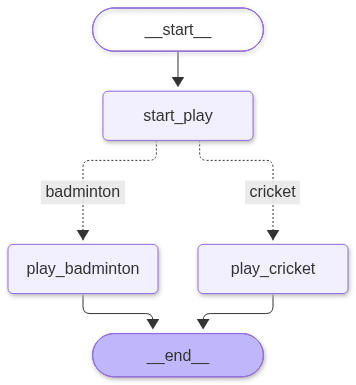

In [33]:
from IPython.display import display, Image
from langgraph.graph import StateGraph, START, END

# Build graph
graph = StateGraph(state_schema=State)

# adding the nodes to the graph
graph.add_node("start_play", start_play)
graph.add_node("play_cricket", play_cricket)
graph.add_node("play_badminton", play_badminton)

# Schedule the flow of the graph
graph.add_edge(START, "start_play")
graph.add_conditional_edges(
	"start_play",
	random_play,
	{"cricket": "play_cricket", "badminton": "play_badminton"},
)
graph.add_edge("play_cricket", END)
graph.add_edge("play_badminton", END)

graph_builder = graph.compile()

display(Image(graph_builder.get_graph().draw_mermaid_png()))

#### 5. Run the graph

`invoke` starts a run with the initial state. The `graph_info` value supplied here is required; the `TypedDict` declaration above does not create it automatically. The returned dictionary contains the final state after the start node and one randomly chosen activity node have run. Because the route is random, repeated runs can produce different final messages.

In [44]:
graph_builder.invoke({"graph_info": "Hey My Name is Ajay Sharma"})

Start Play node has been called
Random play node has been called
Play Cricket node has been called


{'graph_info': 'Hey My Name is Ajay Sharma | Started playing the graph | Playing cricket'}